# Visão IA — Laboratório completo | Colab → Drive → GitHub Pages

**Objetivo:** criar, treinar e publicar um classificador de imagens acessível pelo **celular e notebook**, que recebe fotos da **câmera** ou **galeria**.

**Todas as etapas estão neste notebook**, inclusive a geração da aplicação web. Não é necessário solicitar HTML, CSS ou JavaScript a uma IA.

### Antes de começar
1. Abra este `.ipynb` no Google Colab.
2. Escolha, se disponível, **Ambiente de execução → Alterar o tipo → Versão do ambiente de execução 2026.04 (Python 3.12)**. A opção pode mudar ou deixar de existir no Colab.
3. Use preferencialmente o runtime que mostra **Python 3.12.13 / TensorFlow 2.19.0**, o ambiente que funcionou nos testes desta turma.
4. Escolha **Ambiente de execução → Desconectar e excluir ambiente de execução** para começar do zero.
5. Execute **uma célula por vez e na ordem**. Quando o Colab pedir acesso ao Google Drive, autorize.

**Arquitetura:** Colab/Python treina; Google Drive conserva as fotos e os resultados; TensorFlow.js executa o modelo no navegador; GitHub Pages publica o site estático. Imagens da galeria/câmera são processadas no navegador, não enviadas ao Drive.

> Testado anteriormente com Python 3.12 + TensorFlow 2.19, `tensorflowjs==4.22.0` em `virtualenv`, e os ajustes de Protobuf e setuptools descritos aqui. As dependências podem evoluir; a conversão deve sempre ser verificada com o próprio modelo.

## Etapa 1 — Preparar ambiente e conferir versões
**Não execute uma importação do TensorFlow antes de definir `TF_USE_LEGACY_KERAS`.** Esta célula faz isso na ordem correta. Não instalar `tensorflowjs` diretamente no Colab.

In [48]:
import os, sys, importlib.metadata as md
print('Python:', sys.version.split()[0])
assert sys.version_info[:2] == (3, 12), 'Este roteiro requer Python 3.12. Altere a versão do runtime do Colab.'
%pip install -q "tf-keras==2.19.0" "virtualenv"
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf
from tensorflow import keras
print('TensorFlow:', tf.__version__)
assert tf.__version__.startswith('2.19.'), 'Este notebook foi validado com TensorFlow 2.19.x.'
print('OK — treinamento pronto.')

# 1. Instale a biblioteca de download (via terminal: pip install bing-image-downloader)
# Adicione esta linha antes de importar:
%pip install -q bing-image-downloader
import shutil
from pathlib import Path
from bing_image_downloader import downloader
from PIL import Image
print('OK - Download automatico')

Python: 3.12.13
TensorFlow: 2.19.0
OK — treinamento pronto.
OK - Download automatico


## Etapa 2 — Montar o Google Drive
O Drive guardará o conjunto de imagens (dataset) e uma cópia do site e do modelo já treinados.

In [49]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/teste')
DATA = ROOT / 'dataset'
DATA.mkdir(parents=True, exist_ok=True)
print('Pasta do dataset:', DATA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta do dataset: /content/drive/MyDrive/teste/dataset


## Etapa 3 — Montar o dataset
Crie subpastas dentro de `Meu Drive/VisaoIA/dataset/`, **uma pasta por classe**. Exemplo:
```text
VisaoIA/dataset/
  margaridas/ foto1.jpg, foto2.jpg, ...
  rosas/ foto1.jpg, foto2.jpg, ...
  girassois/ foto1.jpg, foto2.jpg, ...
```
Recomendamos **pelo menos 40–100 fotos variadas por classe**, mas é possível começar com 10 para testar. Para a atividade inicial, rode a próxima célula opcional: ela baixa fotos públicas de flores e copia até 100 por classe **somente se a pasta estiver vazia**. Se já tiver fotos próprias, **pule a célula opcional**.

In [50]:
# OPCIONAL — preparar exemplo de flores para a primeira aula
import shutil
# A biblioteca shutil oferece ferramentas para copiar, mover e organizar arquivos e pastas.
# O arquivo .tgz funciona como um pacote compactado que contém várias imagens organizadas por categoria.
arquivo = tf.keras.utils.get_file(
    'flower_photos.tgz',
    origin='https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
    extract=True
)
origem = Path(arquivo).parent / 'flower_photos'
exemplos = {'daisy':'margaridas', 'roses':'rosas', 'sunflowers':'girassois'}
for ingles, classe in exemplos.items():
    pasta = DATA / classe
    pasta.mkdir(exist_ok=True)
    existentes = [p for p in pasta.iterdir() if p.suffix.lower() in ('.jpg','.jpeg','.png')]
    if existentes:
        print(classe, '— preservadas', len(existentes), 'imagens já existentes')
        continue
    fontes = sorted((origem / ingles).glob('*.jpg'))[:100]
    for foto in fontes:
        shutil.copy2(foto, pasta / foto.name)
    print(classe, '— importadas', len(fontes), 'imagens')

margaridas — preservadas 100 imagens já existentes
rosas — preservadas 100 imagens já existentes
girassois — preservadas 100 imagens já existentes


In [51]:
# 1. Caminhos locais (memória do Colab - evita erros de escrita e atrasos do Drive)
LOCAL_DATA = Path('/content/dataset_local')
LOCAL_BOLSONARO = LOCAL_DATA / 'Jair_Bolsonaro'
print('Local encontrado', LOCAL_BOLSONARO)

if LOCAL_DATA.exists():
    shutil.rmtree(LOCAL_DATA)
LOCAL_BOLSONARO.mkdir(parents=True, exist_ok=True)

Local encontrado /content/dataset_local/Jair Bolsonaro


In [82]:
# 2. Executa o download na memória local do Colab
termos_busca = ["Jair_Bolsonaro"]
print("Iniciando o download das imagens...")

for termo in termos_busca:
    downloader.download(
        termo,
        limit=500,                     # Ajustado para 50 para ser rápido e seguro no Colab
        output_dir='/content/dataset_temporario',
        adult_filter_off=True,
        force_replace=True,
        timeout=300
    )

Iniciando o download das imagens...
[%] Downloading Images to /content/dataset_temporario/Jair_Bolsonaro


[!!] Indexing page: 1

[%] Indexed 50 Images on Page 1.


[%] Downloading Image #1 from https://www.gp1.com.br/media/image_bank/2025/6/jair-bolsonaro-562576.jpg.1200x0_q95_crop.webp
[%] File Downloaded!

[%] Downloading Image #2 from https://www.cic7noticias.com/wp-content/uploads/2024/03/Jair_Bolsonaro_em_24_de_abril_de_2019_2-scaled-compressed.jpg
[%] File Downloaded!

[%] Downloading Image #3 from https://imagenes.elpais.com/resizer/v2/X2HKMY7B5NI2NNXV3ATTYYWK3A.jpg?auth=dab6835a92899a5a38507a78a51c81ec8e67505d0d68938a8f6deb7a8603ad1c&width=1960
[%] File Downloaded!

[%] Downloading Image #4 from https://media.npr.org/assets/img/2023/01/09/gettyimages-1244301563-ed820e8a82fdca03bda0c5b0e422cb716ec3394d-s1200.jpg
[%] File Downloaded!

[%] Downloading Image #5 from https://files.topmediai.com/tts/avatar/39dfea66-a8b5-11ef-972d-00163e04a5e6.jpeg
[%] File Downloaded!

[%] Downloadi

In [74]:
# Move os arquivos baixados da pasta temporária para a pasta correta da classe local
TEMP_DIR = Path('/content/dataset_temporario') / 'Jair_Bolsonaro'
if TEMP_DIR.exists():
    for f in TEMP_DIR.iterdir():
        if f.is_file():
            shutil.move(str(f), str(LOCAL_BOLSONARO / f.name))
    shutil.rmtree('/content/dataset_temporario')

## Etapa 4 — Validar imagens e carregá-las
**Importante:** o nome de cada pasta é o nome da categoria. Não misture imagens diferentes na mesma pasta. As imagens serão redimensionadas para **96 × 96**, em RGB.

In [75]:
IMG_SIZE = (96, 96)
SEED = 42
BATCH = 32
DATA_DIR = Path('/content/drive/MyDrive/teste/dataset')

# 1. Descobre todas as classes dinamicamente pelas pastas do Drive
classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
print('Classes encontradas:', classes)
num_classes = len(classes)
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

# 2. Carrega, valida e converte cada imagem manualmente de forma segura
imagens = []
rotulos = []
extensoes_validas = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

for cls_name in classes:
    cls_path = DATA_DIR / cls_name
    for arquivo in cls_path.iterdir():
        if arquivo.is_file() and arquivo.suffix.lower() in extensoes_validas:
            try:
                # Abre, força conversão para RGB e redimensiona
                with Image.open(arquivo) as img:
                    img = img.convert('RGB')
                    img = img.resize(IMG_SIZE)
                    arr = np.array(img, dtype=np.float32) / 255.0  # Normalização segura [0, 1]

                    if arr.shape == (96, 96, 3):
                        imagens.append(arr)
                        rotulos.append(class_to_idx[cls_name])
            except Exception:
                # Se qualquer arquivo falhar, ele é simplesmente ignorado sem quebrar o código
                pass

X = np.array(imagens)
y = np.array(rotulos, dtype=np.int32)

print(f"Total de imagens válidas carregadas com sucesso: {len(X)}")

# 3. Embaralha e divide manualmente em Treino (80%) e Validação (20%)
np.random.seed(SEED)
indices = np.random.permutation(len(X))
X, y = X[indices], y[indices]

split = int(0.8 * len(X))
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

print(f"Treino: {len(X_train)} imagens | Validação: {len(X_val)} imagens")

# 4. Cria os datasets oficiais do TensorFlow usando arrays NumPy (Zero risco de erro de decode)
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(100).batch(BATCH).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH).prefetch(tf.data.AUTOTUNE)

print('Datasets criados e 100% blindados contra arquivos corrompidos!')

Classes encontradas: ['Jair_Bolsonaro', 'girassois', 'margaridas', 'rosas']
Total de imagens válidas carregadas com sucesso: 346
Treino: 276 imagens | Validação: 70 imagens
Datasets criados e 100% blindados contra arquivos corrompidos!


## Etapa 5 — Criar rede neural convolucional (CNN)
A CNN recebe imagens RGB de `96 × 96`. O treino usa pixels divididos por `255`; **o site fará exatamente a mesma normalização** para evitar classificações inconsistentes.

In [71]:
model=keras.Sequential([
    keras.layers.Input(shape=(96,96,3)),
    keras.layers.Conv2D(24,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(48,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(64,activation='relu'),
    keras.layers.Dense(len(classes),activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_15 (Conv2D)          (None, 96, 96, 24)        672       
                                                                 
 max_pooling2d_15 (MaxPooli  (None, 48, 48, 24)        0         
 ng2D)                                                           
                                                                 
 conv2d_16 (Conv2D)          (None, 48, 48, 48)        10416     
                                                                 
 max_pooling2d_16 (MaxPooli  (None, 24, 24, 48)        0         
 ng2D)                                                           
                                                                 
 conv2d_17 (Conv2D)          (None, 24, 24, 64)        27712     
                                                                 
 max_pooling2d_17 (MaxPooli  (None, 12, 12, 64)       

## Etapa 6 — Treinar, avaliar e visualizar os resultados
Com poucas imagens, a acurácia pode ser baixa; o número apresentado na tela é **pontuação do modelo**, não garantia de acerto. O conjunto de validação aqui é didático (20% das fotos).

Epoch 1/12
9/9 [==============================] - 0s 19ms/step - loss: 0.7984 - accuracy: 0.6739 - val_loss: 0.9598 - val_accuracy: 0.6143
Epoch 2/12
9/9 [==============================] - 0s 16ms/step - loss: 0.7704 - accuracy: 0.7174 - val_loss: 0.9444 - val_accuracy: 0.6857
Epoch 3/12
9/9 [==============================] - 0s 16ms/step - loss: 0.7680 - accuracy: 0.6848 - val_loss: 0.9431 - val_accuracy: 0.6286
Epoch 4/12
9/9 [==============================] - 0s 15ms/step - loss: 0.7594 - accuracy: 0.7065 - val_loss: 0.9162 - val_accuracy: 0.5857
Epoch 5/12
9/9 [==============================] - 0s 17ms/step - loss: 0.7431 - accuracy: 0.7210 - val_loss: 0.9043 - val_accuracy: 0.6571
Epoch 6/12
9/9 [==============================] - 0s 24ms/step - loss: 0.7474 - accuracy: 0.7029 - val_loss: 0.8770 - val_accuracy: 0.6714
Epoch 7/12
9/9 [==============================] - 0s 19ms/step - loss: 0.7203 - accuracy: 0.7428 - val_loss: 0.9077 - val_accuracy: 0.6714
Epoch 8/12
9/9 [===========

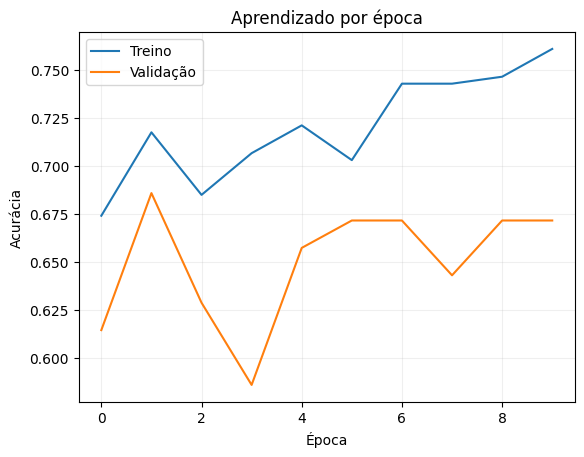

In [76]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)]
)
loss, acc = model.evaluate(val_ds, verbose=0)
print(f'Acurácia de validação: {acc:.1%} | Perda: {loss:.4f}')

import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Aprendizado por época')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Etapa 7 — Salvar o modelo treinado
O arquivo `.h5` permite que o conversor do TensorFlow.js leia a rede Keras legada. A mensagem de aviso dizendo que HDF5 é “legacy” **não indica falha**.

In [78]:
H5=Path('/content/visao_ia.h5')
model.save(str(H5))
assert H5.is_file() and H5.stat().st_size>0
print('Modelo salvo:',H5,'|',H5.stat().st_size,'bytes')

Modelo salvo: /content/visao_ia.h5 | 569680 bytes


/usr/local/lib/python3.12/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


## Etapa 8 — Converter em ambiente isolado (sequência validada)
**Por que um ambiente separado?** `tensorflowjs==4.22.0` exige `packaging` da série 23, enquanto outros pacotes do Colab exigem 24+. Além disso, os testes desta turma identificaram necessidade de `protobuf==6.31.1` e `setuptools==80.9.0` no **ambiente do conversor**.

Esta célula cria o ambiente virtual isolado, instala as bibliotecas, aplica os ajustes e executa a conversão. **Não instala TensorFlow.js no Colab principal**. O `pip check` é mostrado para diagnóstico e pode avisar sobre dependências antigas do conversor; o sucesso real é `Código de retorno: 0` e a geração dos arquivos `model.json` e `.bin`.

> Requer internet para instalar as bibliotecas. As versões foram usadas com sucesso no caso acompanhado em aula; futuras mudanças de pacotes podem demandar manutenção.

In [79]:
import subprocess, shutil
VENV=Path('/content/ambiente_tfjs')
EXPORT=Path('/content/modelo_exportado')
if VENV.exists(): shutil.rmtree(VENV)
if EXPORT.exists(): shutil.rmtree(EXPORT)
EXPORT.mkdir(parents=True)

def rodar(args, *, mostrar_erro=True):
    r=subprocess.run([str(x) for x in args],capture_output=True,text=True)
    if r.returncode!=0:
        if mostrar_erro:
            print('COMANDO:', ' '.join(map(str,args)))
            print((r.stdout+'\n'+r.stderr)[-10000:])
        raise RuntimeError(f'Etapa interrompida (código {r.returncode}). Leia o erro acima.')
    return r

print('1/4 — Criando ambiente virtual...')
rodar([sys.executable,'-m','virtualenv',str(VENV)])
VPY=VENV/'bin/python'
print('2/4 — Instalando TensorFlow.js no ambiente isolado...')
rodar([VPY,'-m','pip','install',
       'tensorflowjs==4.22.0','packaging==23.2',
       'tensorflow==2.19.0','tf-keras==2.19.0'])
print('3/4 — Ajustando dependências que causaram erro durante a aula...')
rodar([VPY,'-m','pip','install','--no-deps','protobuf==6.31.1','setuptools==80.9.0'])
verif=subprocess.run([str(VPY),'-m','pip','check'],capture_output=True,text=True)
print('Verificação de dependências (informativa):',verif.returncode)
if verif.stdout or verif.stderr: print((verif.stdout+verif.stderr)[-3000:])
print('4/4 — Convertendo HDF5 para TensorFlow.js...')
conv=VENV/'bin/tensorflowjs_converter'
r=subprocess.run([str(conv),'--input_format=keras',str(H5),str(EXPORT)],capture_output=True,text=True)
print('Código de retorno:',r.returncode)
if r.returncode!=0:
    print('DETALHES DO ERRO:',r.stderr[-12000:])
    raise RuntimeError('Conversão não concluída. Não é necessário refazer o treinamento: o H5 está salvo.')
assert (EXPORT/'model.json').is_file() and list(EXPORT.glob('*.bin'))
print('CONVERSÃO CONCLUÍDA:',[x.name for x in EXPORT.iterdir()])

1/4 — Criando ambiente virtual...
2/4 — Instalando TensorFlow.js no ambiente isolado...
3/4 — Ajustando dependências que causaram erro durante a aula...
Verificação de dependências (informativa): 1
tensorflow 2.19.0 has requirement protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.3, but you have protobuf 6.31.1.

4/4 — Convertendo HDF5 para TensorFlow.js...
Código de retorno: 0
CONVERSÃO CONCLUÍDA: ['model.json', 'group1-shard1of1.bin']


## Etapa 9 — Criar o arquivo de classes e validar o resultado
Esta célula garante que a ordem das classes que saiu do treinamento seja usada na página web. **Não escreva nomes manualmente, nem mude a ordem.**

In [80]:
import json
(EXPORT/'classes.json').write_text(
    json.dumps({'classes':classes,'image_size':96},ensure_ascii=False,indent=2),encoding='utf-8')
info=json.loads((EXPORT/'classes.json').read_text(encoding='utf-8'))
assert info['classes']==classes and info['image_size']==96
assert (EXPORT/'model.json').exists()
assert len(list(EXPORT.glob('*.bin')))>=1
print('Categorias:',classes)
print('Arquivos exportados:',[p.name for p in EXPORT.iterdir()])

Categorias: ['Jair_Bolsonaro', 'girassois', 'margaridas', 'rosas']
Arquivos exportados: ['model.json', 'group1-shard1of1.bin', 'classes.json']


## Etapa 10 — Gerar automaticamente o site completo
A célula a seguir já contém **HTML + CSS + JavaScript completos**, com seleção da galeria, opção de fotografia, câmera ao vivo, classificação e pontuações. **Não precisa de arquivos externos nem de IA para criar a interface.**

Os arquivos são gerados dentro de `/content/visao_ia_site/`, com o modelo exportado na pasta `model/`. A biblioteca TensorFlow.js no site é carregada por CDN; é preciso conexão para o primeiro carregamento.

In [83]:
SITE=Path('/content/visao_ia_site')
SITE.mkdir(parents=True,exist_ok=True)
print('Pasta da aplicação:', SITE)

Pasta da aplicação: /content/visao_ia_site


In [84]:
# Criar o arquivo index.html automaticamente
(SITE / 'index.html').write_text('<!doctype html>\n<html lang="pt-BR">\n<head>\n  <meta charset="UTF-8" />\n  <meta name="viewport" content="width=device-width, initial-scale=1" />\n  <meta name="theme-color" content="#102a43" />\n  <title>Visão IA — Classificador de imagens</title>\n  <link rel="stylesheet" href="style.css" />\n  <script defer src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@4.22.0/dist/tf.min.js"></script>\n  <script defer src="script.js"></script>\n</head>\n<body>\n  <main class="container">\n    <header><span class="eyebrow">PROJETO EDUCACIONAL · VISÃO COMPUTACIONAL</span><h1>Visão IA</h1><p>Classifique uma imagem usando um modelo treinado no Google Colab.</p></header>\n    <section class="panel">\n      <p id="status" role="status" aria-live="polite">Carregando modelo…</p>\n      <div class="actions">\n        <label class="button primary" for="gallery">Escolher imagem</label>\n        <input id="gallery" type="file" accept="image/*" hidden />\n        <label class="button" for="photo">Tirar foto (celular)</label>\n        <input id="photo" type="file" accept="image/*" capture="environment" hidden />\n        <button type="button" id="startCamera">Abrir câmera ao vivo</button>\n        <button type="button" id="takePhoto" disabled>Capturar da câmera</button>\n        <button type="button" id="stopCamera" disabled>Fechar câmera</button>\n      </div>\n      <div class="preview"><video id="video" autoplay playsinline muted hidden></video><img id="previewImage" alt="Imagem selecionada" hidden /><span id="placeholder">Sua imagem aparecerá aqui.</span></div>\n      <canvas id="captureCanvas" hidden></canvas>\n      <button type="button" id="classify" class="primary classify" disabled>Classificar imagem</button>\n    </section>\n    <section class="panel" aria-live="polite"><h2>Resultado</h2><p id="result">Selecione ou capture uma imagem para começar.</p><div id="scores"></div><p class="footnote">As pontuações representam as saídas do modelo, não garantias de acerto. As imagens são analisadas no próprio navegador.</p></section>\n  </main>\n</body>\n</html>\n', encoding='utf-8')
print('Criado: index.html')

Criado: index.html


In [85]:
# Criar o arquivo style.css automaticamente
(SITE / 'style.css').write_text(':root{font-family:system-ui,-apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif;background:#f2f6fa;color:#102a43}*{box-sizing:border-box}body{margin:0}.container{width:min(820px,94%);margin:35px auto 60px}header{padding:15px 3px 20px}.eyebrow{font-size:.75rem;color:#356c99;letter-spacing:.13em;font-weight:800}h1{font-size:2.4rem;margin:7px 0}header p{color:#526779}.panel{padding:24px;background:#fff;border:1px solid #e2eaf0;box-shadow:0 6px 25px #102a4311;border-radius:18px;margin-bottom:18px}.actions{display:flex;flex-wrap:wrap;gap:10px;margin:20px 0}button,.button{appearance:none;border:1px solid #bdcddd;background:white;border-radius:10px;padding:12px 15px;font-weight:650;font-size:.95rem;color:#163d61;cursor:pointer;text-align:center}button.primary,.button.primary{background:#135d9c;border-color:#135d9c;color:white}button:disabled{opacity:.4;cursor:not-allowed}.preview{background:#f4f7fa;border:2px dashed #cbd9e3;border-radius:12px;min-height:190px;display:flex;justify-content:center;align-items:center;overflow:hidden;color:#687b8b}.preview video,.preview img{max-height:380px;width:100%;object-fit:contain}.preview video[hidden],.preview img[hidden]{display:none}.classify{margin-top:15px;width:100%;font-size:1.1rem}h2{font-size:1.2rem;margin:0 0 15px}.score{margin:12px 0}.scoreHead{display:flex;justify-content:space-between;margin-bottom:5px;font-size:.95rem}.track{height:10px;background:#e5eef6;border-radius:20px;overflow:hidden}.fill{height:100%;background:#2176b6;border-radius:20px}.footnote{font-size:.8rem;color:#687d8c;line-height:1.5}#status{margin:0;font-weight:650;color:#355c7d}@media(max-width:570px){.panel{padding:17px}.actions{display:grid;grid-template-columns:1fr 1fr}.actions>*{font-size:.83rem;padding:11px 7px}h1{font-size:2rem}}\n', encoding='utf-8')
print('Criado: style.css')

Criado: style.css


In [86]:
# Criar o arquivo script.js automaticamente
(SITE / 'script.js').write_text('\'use strict\';\nconst $ = id => document.getElementById(id);\nlet model = null;\nlet names = [];\nlet size = 96;\nlet stream = null;\nlet imageReady = false;\nconst status = text => { $(\'status\').textContent = text; };\nfunction stopCamera(){\n  if (stream) { stream.getTracks().forEach(track => track.stop()); stream = null; }\n  $(\'video\').hidden = true;\n  $(\'stopCamera\').disabled = true;\n  $(\'takePhoto\').disabled = true;\n}\nfunction setImage(url){\n  stopCamera();\n  const img=$(\'previewImage\');\n  imageReady=false; $(\'classify\').disabled=true;\n  img.onload=()=>{imageReady=true;$(\'classify\').disabled=!model;status(\'Imagem pronta para classificar.\');};\n  img.onerror=()=>status(\'Não foi possível abrir esta imagem.\');\n  img.src=url; img.hidden=false; $(\'placeholder\').hidden=true;\n  $(\'result\').textContent=\'Clique em “Classificar imagem”.\'; $(\'scores\').replaceChildren();\n}\nfunction readFile(file){\n  if (!file) return;\n  if (!file.type.startsWith(\'image/\')) {status(\'Escolha um arquivo de imagem.\');return;}\n  const reader=new FileReader(); reader.onload=()=>setImage(reader.result); reader.onerror=()=>status(\'Falha ao ler imagem.\');reader.readAsDataURL(file);\n}\n$(\'gallery\').addEventListener(\'change\', e=>{readFile(e.target.files[0]);e.target.value=\'\';});\n$(\'photo\').addEventListener(\'change\', e=>{readFile(e.target.files[0]);e.target.value=\'\';});\n$(\'startCamera\').addEventListener(\'click\',async()=>{\n  if (!navigator.mediaDevices?.getUserMedia){status(\'Câmera ao vivo indisponível. Use “Tirar foto” ou “Escolher imagem”.\');return;}\n  try{\n    stopCamera();\n    stream=await navigator.mediaDevices.getUserMedia({video:{facingMode:{ideal:\'environment\'}},audio:false});\n    $(\'video\').srcObject=stream; $(\'video\').hidden=false; $(\'previewImage\').hidden=true; $(\'placeholder\').hidden=true;\n    $(\'classify\').disabled=true; imageReady=false;\n    $(\'takePhoto\').disabled=false; $(\'stopCamera\').disabled=false;\n    status(\'Câmera ligada. Clique em “Capturar da câmera”.\');\n  }catch(err){status(\'Não foi possível abrir a câmera: \'+err.message+\' — use a galeria se preferir.\');}\n});\n$(\'takePhoto\').addEventListener(\'click\',()=>{\n  const video=$(\'video\');\n  if (!stream || !video.videoWidth){status(\'Aguarde a câmera carregar.\');return;}\n  const canvas=$(\'captureCanvas\');canvas.width=video.videoWidth;canvas.height=video.videoHeight;\n  canvas.getContext(\'2d\').drawImage(video,0,0);\n  setImage(canvas.toDataURL(\'image/jpeg\',0.92));\n});\n$(\'stopCamera\').addEventListener(\'click\',()=>{stopCamera();$(\'placeholder\').hidden=!$(\'previewImage\').hidden;status(\'Câmera desligada.\');});\nwindow.addEventListener(\'pagehide\',stopCamera);\n$(\'classify\').addEventListener(\'click\',async()=>{\n  if(!model || !imageReady)return;\n  $(\'classify\').disabled=true; status(\'Classificando…\');\n  try{\n    // Mesmo pré-processamento do Colab v2: RGB, 96 × 96, valores / 255.\n    const scores=await tf.tidy(()=>{\n      const pixels=tf.browser.fromPixels($(\'previewImage\'),3);\n      const batch=tf.image.resizeBilinear(pixels,[size,size]).toFloat().div(255).expandDims(0);\n      const out=model.predict(batch);\n      return Array.from(out.dataSync());\n    });\n    if(scores.length!==names.length)throw new Error(`Modelo possui ${scores.length} saídas, mas classes.json possui ${names.length} categorias.`);\n    const ranked=scores.map((p,i)=>({p,name:names[i]})).sort((a,b)=>b.p-a.p);\n    $(\'result\').textContent=`Classe mais provável: ${ranked[0].name} (${(ranked[0].p*100).toFixed(1)}%)`;\n    $(\'scores\').replaceChildren();\n    for(const item of ranked){\n      const row=document.createElement(\'div\');row.className=\'score\';\n      const head=document.createElement(\'div\');head.className=\'scoreHead\';\n      const title=document.createElement(\'span\');title.textContent=item.name;\n      const number=document.createElement(\'span\');number.textContent=(item.p*100).toFixed(1)+\'%\';\n      head.append(title,number);const track=document.createElement(\'div\');track.className=\'track\';\n      const fill=document.createElement(\'div\');fill.className=\'fill\';fill.style.width=Math.min(100,Math.max(0,item.p*100))+\'%\';\n      track.append(fill);row.append(head,track);$(\'scores\').append(row);\n    }\n    status(\'Classificação concluída.\');\n  }catch(err){status(\'Erro de classificação: \'+err.message);console.error(err);}\n  finally{$(\'classify\').disabled=!imageReady||!model;}\n});\n(async()=>{\n  try{\n    if(typeof tf===\'undefined\')throw new Error(\'Biblioteca TensorFlow.js não carregou. Verifique sua conexão com a internet.\');\n    const response=await fetch(\'./model/classes.json\');if(!response.ok)throw new Error(`classes.json: HTTP ${response.status}`);\n    const classes=await response.json();\n    if(!Array.isArray(classes.classes)||!classes.classes.length)throw new Error(\'classes.json não contém lista "classes".\');\n    names=classes.classes;size=Number(classes.image_size)||96;\n    model=await tf.loadLayersModel(\'./model/model.json\');\n    status(`Modelo carregado: ${names.length} categorias. Escolha uma foto.`);\n    $(\'classify\').disabled=!imageReady;\n  }catch(err){status(\'Modelo ainda não disponível: \'+err.message);console.error(err);}\n})();\n', encoding='utf-8')
print('Criado: script.js')

Criado: script.js


## Etapa 11 — Montar a pasta `model`, testar e criar ZIP pronto para o GitHub
O ZIP terá `index.html` **na raiz**. Este é o arquivo a enviar ao GitHub, **não** o ZIP contendo somente o modelo.

In [87]:
import zipfile, shutil
SITE_MODEL=SITE/'model'
if SITE_MODEL.exists():shutil.rmtree(SITE_MODEL)
shutil.copytree(EXPORT,SITE_MODEL)
for required in ['index.html','style.css','script.js','model/model.json','model/classes.json']:
    assert (SITE/required).is_file(),f'Arquivo ausente: {required}'
assert list(SITE_MODEL.glob('*.bin')),'Arquivo de pesos .bin ausente!'
ZIP=Path('/content/Visao_IA_SITE_PRONTO_GITHUB.zip')
with zipfile.ZipFile(ZIP,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in SITE.rglob('*'):
        if file.is_file():z.write(file,file.relative_to(SITE).as_posix())
with zipfile.ZipFile(ZIP) as z:
    arquivos=z.namelist()
    assert 'index.html' in arquivos and 'model/model.json' in arquivos
print('SITE GERADO COM SUCESSO:',ZIP)
print('Arquivos contidos no ZIP:')
for f in arquivos:print('  ',f)

SITE GERADO COM SUCESSO: /content/Visao_IA_SITE_PRONTO_GITHUB.zip
Arquivos contidos no ZIP:
   script.js
   index.html
   style.css
   model/model.json
   model/group1-shard1of1.bin
   model/classes.json


## Etapa 12 — Guardar backup no Drive e baixar o ZIP final
O Drive mantém tanto os arquivos do modelo quanto o ZIP do site. O download pode abrir uma janela do navegador.

In [88]:
BACKUP=ROOT/'publicacao'
BACKUP.mkdir(parents=True,exist_ok=True)
shutil.copy2(ZIP,BACKUP/ZIP.name)
shutil.copy2(H5,BACKUP/H5.name)
print('Backup salvo em:',BACKUP)
from google.colab import files
files.download(str(ZIP))

Backup salvo em: /content/drive/MyDrive/teste/publicacao


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Etapa 13 — Testar localmente no Windows (opcional, recomendado)
1. Extraia o ZIP final em `C:\Projetos\visao-ia`.
2. Abra **somente essa pasta** no VS Code ou Git Bash.
3. Execute `python -m http.server 8000`.
4. Abra `http://localhost:8000` no navegador do notebook.
5. Selecione uma foto e clique em **Classificar imagem**. Também poderá testar o botão de câmera.
6. Pare o servidor com `Ctrl+C` ao concluir.

**Não abra o `index.html` diretamente por duplo clique (`file://`)**, pois o navegador pode bloquear o carregamento do modelo. O celular será testado após o Pages estar online via HTTPS.

## Etapa 14 — Publicar no GitHub Pages (pela interface web)
1. Entre em [github.com/new](https://github.com/new) e crie um repositório **público**, por exemplo `visao-ia`.
2. Extraia `Visao_IA_SITE_PRONTO_GITHUB.zip` e envie **seu conteúdo**, não o ZIP, para a raiz do repositório (`Add file → Upload files`). Preserve a subpasta `model/`.
3. Finalize em `Commit changes`.
4. Vá a **Settings → Pages → Deploy from a branch**. Selecione **main** e **/(root)** e clique **Save**.
5. Abra `https://SEU-USUARIO.github.io/visao-ia/` (substitua o usuário e, se necessário, o nome do repositório).
6. No **celular**, abra o mesmo link HTTPS: selecione uma imagem da galeria ou tire uma foto. Para câmera ao vivo, conceda permissão quando o navegador solicitar.


**Alternativa via Git Bash:**
```bash
git init
git branch -M main
git add .
git commit -m "Publicacao do Visao IA"
git remote add origin https://github.com/SEU-USUARIO/visao-ia.git
git push -u origin main
```
Se `origin` já existir, consulte `git remote -v` e altere com `git remote set-url origin https://github.com/SEU-USUARIO/visao-ia.git`. **Nunca use `git@https://...`**.

Quando quiser retreinar, repita as etapas do Colab e substitua no GitHub os arquivos da pasta `model/`. Você não precisa republicar as imagens do dataset.